# Task 1 — Prior Distribution Analysis

**Data generation**

Run the following command from the repository root:

```bash
flashsim generate -n 50000 --seed 5 -o data/t2_full.h5
```

**Environment**

Use the Python environment configured according to the project's installation instructions.

The notebook assumes that the current working directory is the repository root.


## T1.1 — Vertex Distribution

### T1.1.1 — Prior Distributions

**Question:** What are the distributions of $x_0, y_0, E, t_0, r_0$, and $r_0^2$?

We use 50,000 simulated events (seed = 5) to visualize the prior distributions using normalized histograms.


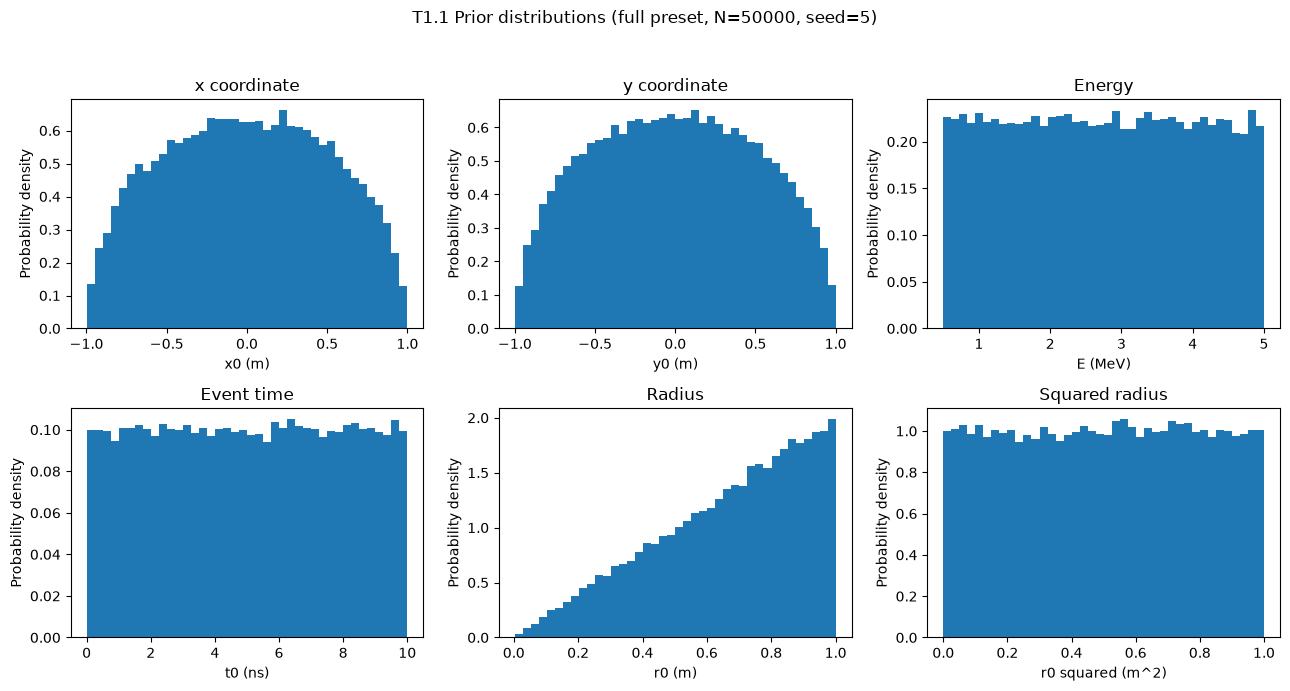

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from prob_reco_sbi.flash import load

data = load("data/t2_full.h5") #load data

x = data.truth.x
y = data.truth.y
E = data.truth.energy
t0 = data.truth.t0   #extract event parameters

r0 = np.sqrt(x**2 + y**2)
r0_squared = r0**2
# T1.1: Histograms of prior parameters
fig, axes = plt.subplots(2, 3, figsize=(13, 7)) 
variables = [
    (x, "x coordinate", "x0 (m)"),
    (y, "y coordinate", "y0 (m)"),
    (E, "Energy", "E (MeV)"),
    (t0, "Event time", "t0 (ns)"),
    (r0, "Radius", "r0 (m)"),
    (r0_squared, "Squared radius", "r0 squared (m^2)")
]

for ax, (values, title, xlabel) in zip(axes.flat, variables):  #axes.flat会让我们按顺序遍历这 6 个绘图区域
    ax.hist(values, bins=40, density=True) #绘制归一化的直方图
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability density")

fig.suptitle("T1.1 Prior distributions (full preset, N=50000, seed=5)")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("T1.1_prior_histograms.png", dpi=200)
plt.show()

**Observations:**

* $E$ and $t_0$ are approximately uniform.
* $x_0$ and $y_0$ have higher densities near zero.
* $r_0$ increases with radius, while $r_0^2$ is approximately uniform.


### T1.1.2 — 2D Vertex Distribution

**Question:** How are the event vertices distributed in the detector?

We plot the event positions $(x_0,y_0)$ to examine their spatial distribution.


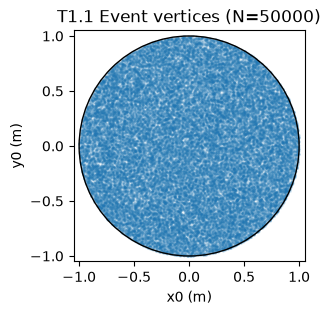

In [19]:
# T1.1: 2D distribution of event vertices
fig, ax = plt.subplots(figsize=(3, 3))
ax.scatter(x, y, s=1, alpha=0.15)

# Draw detector boundary
circle = plt.Circle((0, 0), 1.0, fill=False)
ax.add_patch(circle)

ax.set_xlabel("x0 (m)")
ax.set_ylabel("y0 (m)")
ax.set_title("T1.1 Event vertices (N=50000)")

ax.set_aspect("equal") #让 x 轴和 y 轴的单位长度在图上保持一致
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-1.05, 1.05)

plt.savefig("T1.1_vertices.png", dpi=200)
plt.show()

**Observation:**

The vertices are approximately uniformly distributed over the area of the circular detector, with no preferred direction.


### T1.1.3 — Why Is $r_0$ Not Uniform While $r_0^2$ Is?

For uniformly distributed vertices in a disk of radius \(R\):

$$
p(r_0)=\frac{2r_0}{R^2},\qquad p(r_0^2)=\frac{1}{R^2}
$$

Outer rings have larger areas and therefore contain more events. Thus, \(r_0\) is not uniform, while $r_0^2$ is uniform.

Below is a comparison between event counts in two rings of equal width, the difference is very distinct.

In [24]:
# Compare event counts in two rings of equal width
inner = (r0 >= 0.05) & (r0 < 0.15)
outer = (r0 >= 0.85) & (r0 < 0.95)

n_inner = np.sum(inner)
n_outer = np.sum(outer)
print("Inner ring:", n_inner)
print("Outer ring:", n_outer)
print("Count ratio:", n_outer / n_inner)
print("Expected ratio:", 9.0)

Inner ring: 1002
Outer ring: 9068
Count ratio: 9.049900199600799
Expected ratio: 9.0


## T1.2 — Why Does the Prior Matter?

**Question:** How does the prior affect neural posterior estimation (NPE)?

According to Bayes' theorem:

$$
p(\theta\mid x)\propto p(x\mid\theta)p(\theta)
$$

The prior influences the posterior and restricts the allowed parameter range.

* At $E=0.6 MeV$ or $r_0=0.95 m$, the posterior may be truncated near the prior boundaries.
* An 8 MeV event lies outside the training prior $(0.5–5 MeV)$, so NPE predictions may be unreliable.
